# Comparação entre Q-learning e Sarsa no Taxi-v4 determinístico

Serão realizados cinco treinamentos independentes para cada algoritmo,
utilizando os mesmos hiperparâmetros.

As curvas de aprendizado serão comparadas pela recompensa acumulada
por episódio, com média móvel de 100 episódios.

Cada q-table final será avaliada em 100 episódios sem exploração,
registrando os timesteps e a conclusão da tarefa.

In [1]:
import random
import sys
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

project_root = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "algorithms").is_dir()
)

sys.path.insert(0, str(project_root))

from algorithms.QLearning import QLearning
from algorithms.Sarsa import Sarsa

data_dir = project_root / "data"
data_dir.mkdir(exist_ok=True)

alpha = 0.5
gamma = 0.7
epsilon = 0.2
epsilon_min = 0.05
epsilon_dec = 0.99
episodes = 10000

executions = 5
evaluation_episodes = 100
window = 100

In [2]:
algorithms = {
    "Q-learning": QLearning,
    "Sarsa": Sarsa,
}

filenames = {
    "Q-learning": data_dir / "q-table-deterministic-taxidriver.csv",
    "Sarsa": data_dir / "q-table-sarsa-deterministic.csv",
}

training_results = {}

for name, algorithm in algorithms.items():
    all_rewards = []
    q_tables = []

    for execution in range(executions):
        print(f"\n{name}: treinamento {execution + 1}/{executions}")

        # Controla as fontes de aleatoriedade usadas pelas classes.
        random.seed(execution)

        env = gym.make("Taxi-v4")
        env.reset(seed=execution)
        env.action_space.seed(execution)

        agent = algorithm(
            env,
            alpha=alpha,
            gamma=gamma,
            epsilon=epsilon,
            epsilon_min=epsilon_min,
            epsilon_dec=epsilon_dec,
            episodes=episodes,
        )

        q_table, rewards = agent.train(str(filenames[name]))

        q_tables.append(q_table.copy())
        all_rewards.append(rewards)

        env.close()

    training_results[name] = {
        "q_tables": np.array(q_tables),
        "rewards": np.array(all_rewards),
    }

print("\nTreinamentos concluídos.")


Q-learning: treinamento 1/5
Episodes: 10000
Q-learning: treinamento 2/5
Episodes: 10000
Q-learning: treinamento 3/5
Episodes: 10000
Q-learning: treinamento 4/5
Episodes: 10000
Q-learning: treinamento 5/5
Episodes: 10000
Sarsa: treinamento 1/5
Episodes: 10000
Sarsa: treinamento 2/5
Episodes: 10000
Sarsa: treinamento 3/5
Episodes: 10000
Sarsa: treinamento 4/5
Episodes: 10000
Sarsa: treinamento 5/5
Episodes: 10000
Treinamentos concluídos.


In [3]:
for name, result in training_results.items():
    print(name)
    print("  Rewards:", result["rewards"].shape)
    print("  Q-tables:", result["q_tables"].shape)

Q-learning
  Rewards: (5, 10000)
  Q-tables: (5, 500, 6)
Sarsa
  Rewards: (5, 10000)
  Q-tables: (5, 500, 6)


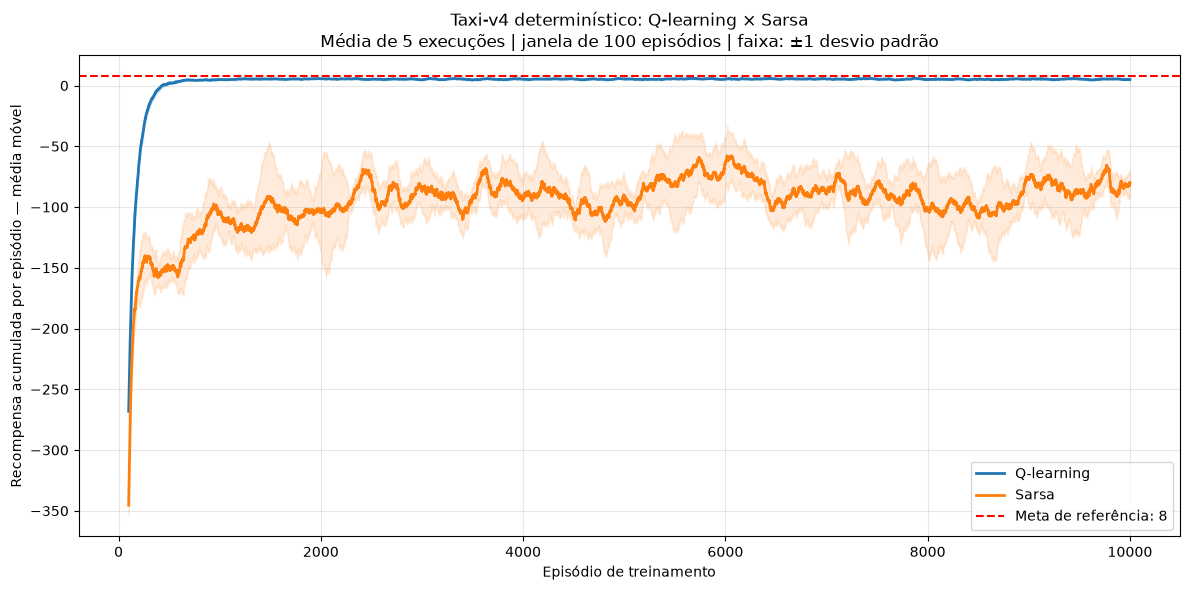

In [4]:
#Gráfico com média móvel
def moving_average(values, window):
    weights = np.ones(window) / window
    return np.convolve(values, weights, mode="valid")


reward_goal = gym.spec("Taxi-v4").reward_threshold
episodes_axis = np.arange(window, episodes + 1)

colors = {
    "Q-learning": "tab:blue",
    "Sarsa": "tab:orange",
}

plt.figure(figsize=(12, 6))

for name, result in training_results.items():
    smoothed_rewards = np.array([
        moving_average(rewards, window)
        for rewards in result["rewards"]
    ])

    mean_rewards = np.mean(smoothed_rewards, axis=0)
    std_rewards = np.std(smoothed_rewards, axis=0)

    plt.plot(
        episodes_axis,
        mean_rewards,
        color=colors[name],
        linewidth=2,
        label=name,
    )

    plt.fill_between(
        episodes_axis,
        mean_rewards - std_rewards,
        mean_rewards + std_rewards,
        color=colors[name],
        alpha=0.15,
    )

plt.axhline(
    reward_goal,
    color="red",
    linestyle="--",
    label=f"Meta de referência: {reward_goal:g}",
)

plt.xlabel("Episódio de treinamento")
plt.ylabel("Recompensa acumulada por episódio — média móvel")
plt.title(
    "Taxi-v4 determinístico: Q-learning × Sarsa\n"
    f"Média de {executions} execuções | "
    f"janela de {window} episódios | faixa: ±1 desvio padrão"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
#Avaliando as tabelas em 100 episódios
def evaluate_agent(q_table, seeds, is_rainy=False):
    env = gym.make("Taxi-v4", is_rainy=is_rainy, rainy_probability=0.6)

    timesteps = []
    successes = []

    for seed in seeds:
        state, _ = env.reset(seed=seed)

        terminated = False
        truncated = False
        steps = 0

        while not (terminated or truncated):
            action = int(np.argmax(q_table[state]))

            state, reward, terminated, truncated, _ = env.step(action)
            steps += 1

        timesteps.append(steps)
        successes.append(terminated)

    env.close()

    return np.array(timesteps), np.array(successes)


# Mesmos cenários iniciais para todas as tabelas.
evaluation_seeds = range(1000, 1000 + evaluation_episodes)

evaluation_results = {}

for name, result in training_results.items():
    all_timesteps = []
    all_successes = []

    for q_table in result["q_tables"]:
        timesteps, successes = evaluate_agent(
            q_table,
            evaluation_seeds,
        )

        all_timesteps.append(timesteps)
        all_successes.append(successes)

    evaluation_results[name] = {
        "timesteps": np.array(all_timesteps),
        "successes": np.array(all_successes),
    }

print("Avaliações concluídas.")

Avaliações concluídas.


In [ ]:
for name, result in evaluation_results.items():
    print(f"\n{name}")

    for execution, (timesteps, successes) in enumerate(
        zip(result["timesteps"], result["successes"]),
        start=1,
    ):
        completed_steps = timesteps[successes]

        if len(completed_steps) > 0:
            mean_steps = np.mean(completed_steps)
            std_steps = np.std(completed_steps)

            statistics = (
                f"média = {mean_steps:.2f} | "
                f"desvio padrão = {std_steps:.2f}"
            )
        else:
            statistics = "nenhuma tarefa concluída"

        print(
            f"Execução {execution}: "
            f"sucessos = {successes.sum()}/{len(successes)} | "
            f"{statistics}"
        )


Q-learning
Execução 1: sucessos = 100/100 | média = 13.37 | desvio padrão = 2.93
Execução 2: sucessos = 100/100 | média = 13.37 | desvio padrão = 2.93
Execução 3: sucessos = 100/100 | média = 13.37 | desvio padrão = 2.93
Execução 4: sucessos = 100/100 | média = 13.37 | desvio padrão = 2.93
Execução 5: sucessos = 100/100 | média = 13.37 | desvio padrão = 2.93

Sarsa
Execução 1: sucessos = 43/100 | média = 14.47 | desvio padrão = 4.96
Execução 2: sucessos = 53/100 | média = 14.15 | desvio padrão = 3.73
Execução 3: sucessos = 41/100 | média = 13.73 | desvio padrão = 3.49
Execução 4: sucessos = 75/100 | média = 14.05 | desvio padrão = 3.75
Execução 5: sucessos = 58/100 | média = 13.97 | desvio padrão = 4.25


## Avaliação das políticas determinísticas no ambiente com chuva

Nesta etapa as q-tables treinadas no ambiente determinístico serão
avaliadas no Taxi-v4 com is_rainy=True e rainy_probability=0.6

In [8]:
rainy_transfer_results = {}

for name, result in training_results.items():
    all_timesteps = []
    all_successes = []

    for q_table in result["q_tables"]:
        timesteps, successes = evaluate_agent(
            q_table,
            evaluation_seeds,
            is_rainy=True,
        )

        all_timesteps.append(timesteps)
        all_successes.append(successes)

    rainy_transfer_results[name] = {
        "timesteps": np.array(all_timesteps),
        "successes": np.array(all_successes),
    }

print("Avaliação das tabelas determinísticas na chuva concluída.")

Avaliação das tabelas determinísticas na chuva concluída.


In [9]:
def completion_statistics(timesteps, successes):
    completed_steps = timesteps[successes]

    if len(completed_steps) == 0:
        return np.nan, np.nan

    return np.mean(completed_steps), np.std(completed_steps)


for name in algorithms:
    print(f"\n{name}")
    

    for execution in range(executions):
        scenarios = [
            ("Determinístico", evaluation_results),
            ("Chuvoso", rainy_transfer_results),
        ]

        for environment_name, results in scenarios:
            timesteps = results[name]["timesteps"][execution]
            successes = results[name]["successes"][execution]

            mean_steps, std_steps = completion_statistics(
                timesteps,
                successes,
            )

            success_count = f"{successes.sum()}/{len(successes)}"

            print(
                f"Execução {execution + 1} | "
                f"Ambiente: {environment_name} | "
                f"Sucessos: {success_count} | "
                f"Média: {mean_steps:.2f} | "
                f"Desvio padrão: {std_steps:.2f}"
            )

print("\n* Timesteps apenas dos episódios concluídos.")
print("nan indica que nenhum episódio foi concluído.")


Q-learning
Execução 1 | Ambiente: Determinístico | Sucessos: 100/100 | Média: 13.37 | Desvio padrão: 2.93
Execução 1 | Ambiente: Chuvoso | Sucessos: 97/100 | Média: 26.92 | Desvio padrão: 10.81
Execução 2 | Ambiente: Determinístico | Sucessos: 100/100 | Média: 13.37 | Desvio padrão: 2.93
Execução 2 | Ambiente: Chuvoso | Sucessos: 99/100 | Média: 27.06 | Desvio padrão: 10.76
Execução 3 | Ambiente: Determinístico | Sucessos: 100/100 | Média: 13.37 | Desvio padrão: 2.93
Execução 3 | Ambiente: Chuvoso | Sucessos: 96/100 | Média: 26.48 | Desvio padrão: 9.98
Execução 4 | Ambiente: Determinístico | Sucessos: 100/100 | Média: 13.37 | Desvio padrão: 2.93
Execução 4 | Ambiente: Chuvoso | Sucessos: 95/100 | Média: 26.58 | Desvio padrão: 10.87
Execução 5 | Ambiente: Determinístico | Sucessos: 100/100 | Média: 13.37 | Desvio padrão: 2.93
Execução 5 | Ambiente: Chuvoso | Sucessos: 97/100 | Média: 26.77 | Desvio padrão: 10.89

Sarsa
Execução 1 | Ambiente: Determinístico | Sucessos: 43/100 | Média: 1

### Comparação do desempenho nos dois ambientes

Todos os agentes apresentados abaixo foram treinados no ambiente
determinístico e avaliados em dois ambientes: determinístico e chuvoso(não determinístico).

O primeiro painel compara a taxa de sucesso.
O segundo compara a média de timesteps das tarefas concluídas.

As barras representam a média dos resultados dos cinco treinamentos.
Cada ponto representa o resultado de uma das cinco q-tables,
avaliada em 100 episódios.

Os timesteps devem ser interpretados junto com a taxa de sucesso,
pois episódios sem conclusão não entram na média de duração.

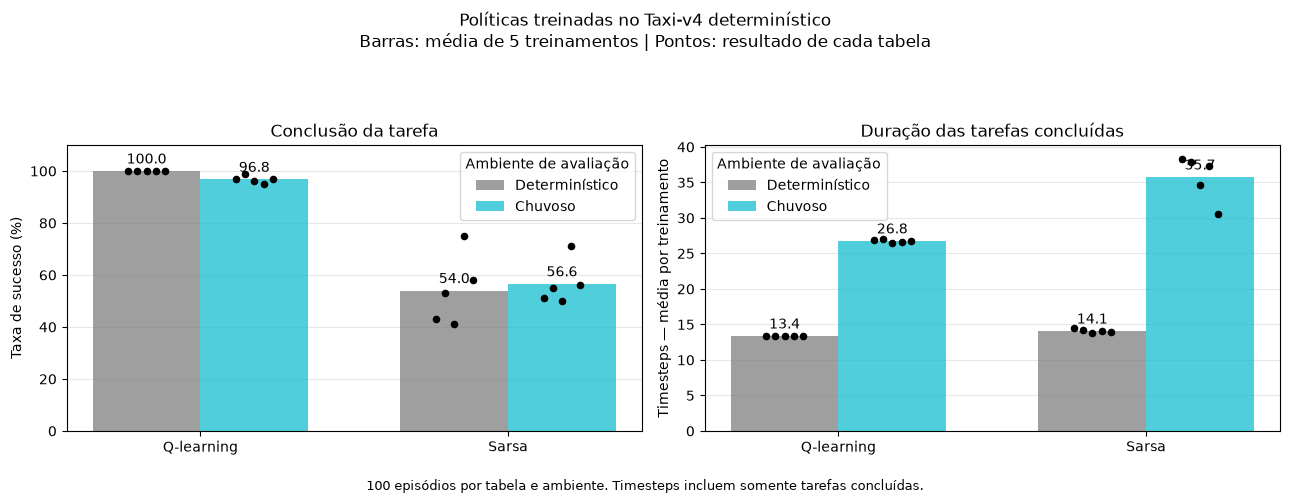

In [10]:
names = list(algorithms.keys())
x = np.arange(len(names))
width = 0.35

scenarios = [
    ("Determinístico", evaluation_results, "tab:gray"),
    ("Chuvoso", rainy_transfer_results, "tab:cyan"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for scenario_index, (label, results, color) in enumerate(scenarios):
    positions = x + (scenario_index - 0.5) * width

    success_rates = []
    mean_timesteps = []

    for name in names:
        timesteps = results[name]["timesteps"]
        successes = results[name]["successes"]

        # Taxa de sucesso de cada uma das cinco tabelas.
        rates = successes.mean(axis=1) * 100

        # Média de passos das entregas concluídas, por tabela.
        steps_per_run = np.array([
            steps[completed].mean() if completed.any() else np.nan
            for steps, completed in zip(timesteps, successes)
        ])

        success_rates.append(rates)
        mean_timesteps.append(steps_per_run)

    metrics = [
        np.array(success_rates),
        np.array(mean_timesteps),
    ]

    for ax, values in zip(axes, metrics):
        # Cada linha contém os resultados das cinco tabelasde um algoritmo.
        means = np.nanmean(values, axis=1)

        bars = ax.bar(
            positions,
            means,
            width=width,
            color=color,
            alpha=0.75,
            label=label,
        )

        ax.bar_label(bars, fmt="%.1f", padding=3)

        # Pequeno deslocamento horizontal para enxergar resultados iguais de diferentes treinamentos.
        offsets = np.linspace(-0.06, 0.06, values.shape[1])

        for position, run_values in zip(positions, values):
            ax.scatter(
                position + offsets,
                run_values,
                color="black",
                s=20,
                zorder=3,
            )

axes[0].set_title("Conclusão da tarefa")
axes[0].set_ylabel("Taxa de sucesso (%)")
axes[0].set_ylim(0, 110)

axes[1].set_title("Duração das tarefas concluídas")
axes[1].set_ylabel("Timesteps — média por treinamento")
axes[1].set_ylim(bottom=0)
axes[1].margins(y=0.20)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(names)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Ambiente de avaliação")

fig.suptitle(
    "Políticas treinadas no Taxi-v4 determinístico\n"
    "Barras: média de 5 treinamentos | Pontos: resultado de cada tabela"
)

fig.text(
    0.5,
    0.02,
    "100 episódios por tabela e ambiente. "
    "Timesteps incluem somente tarefas concluídas.",
    ha="center",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.06, 1, 0.90])
plt.show()